In [6]:
import sys
import os
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt

from sklearn.decomposition import PCA


sys.path.append(os.path.join(os.getcwd(), '../'))
from utils_fly import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [7]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/fly-2023-schaffer/src/manifold/../../../../utils/train_utils.py'>

In [8]:
dims = 3

read_ids = list(range(0, 9+1))
# read_ids = [0,	# paper
# 			1,	# nice states
# 			2,	# nice manifold
# 			5,	# variety
# 			6,	# nice quiescence
# 			7,	# nice states
# 			9,	# nice heatmap
# 			11]	# variety
# read_ids = [0]
plot_id = 0

In [9]:
# read

path = os.path.join(read_utils.get_data_path(), 'brain/incomplete/no_pickle/flailing')
(file_ids, filenames,
 traces,
 states, markers) = read_utils.get_datas(path, read_ids, with_markers=False)

# # clear nan values
# for i in range(len(file_ids)):
# 	mask = markers[i].notna().all(axis=1)
#
# 	traces[i] = traces[i][mask]
# 	markers[i] = markers[i][mask]
# 	states[i] = states[i][mask]
#
# 	#filenames[i] = filenames[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

In [ ]:
# prep

# nothing to do

In [10]:
selection_bhl = ['walk', 'still', 'front-groom', 'back-groom', 'abdomen-move', 'background']

plot_idx = file_ids.index(plot_id)

# states = [ds[selection_bhl] for ds in states]

In [11]:
(modes_manifold,
 recos_manifold,
 loads_pca_man,
 vars_expl_mans) = train_utils.get_manifolds_pca(traces, zscore=False,
												 n_pc=dims)

In [12]:
save = False

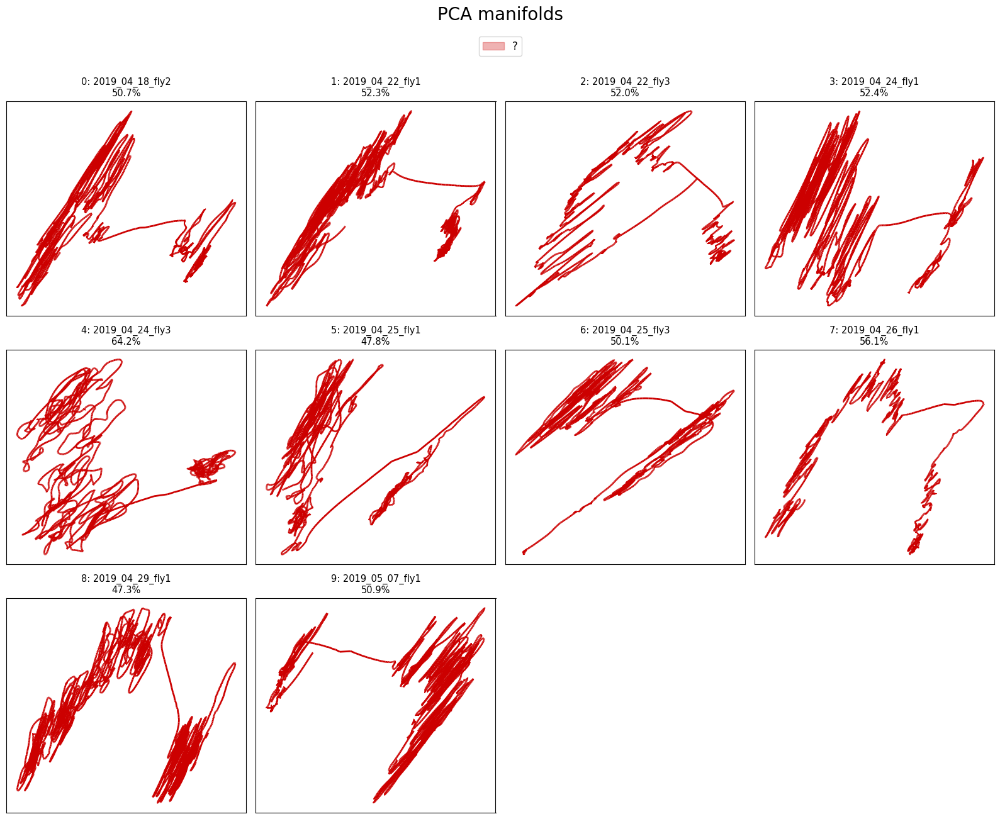

52.4%


In [13]:
plot_utils.plot_manifolds([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
						  modes_manifold, states,
						  [vx[:2] for vx in vars_expl_mans], None,
						  title='PCA manifolds', top_space=1,
						  save_path=f'../../out/plots/manifolds/{dims}-dim-PCA' if save else None)

In [14]:
# plot_utils.plot_manifolds_3d([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
# 							 modes_manifold, states,
# 							 [vx[:3] for vx in vars_expl_mans], None,
# 							 title='PCA manifolds', top_space=1,
# 							 save_path=f'../../out/plots/manifolds/{dims}-dim-PCA_3d' if save else None)

In [31]:
traces_manifolds_indices = [np.argsort(xloads_pca_man[0, :]) for xloads_pca_man in loads_pca_man]

traces_sorted = [t.iloc[:, t_man_idx.tolist()] for t, t_man_idx in zip(traces, traces_manifolds_indices)]

traces_manifolds_sorted = [t_man.iloc[:, t_man_idx.tolist()] for t_man, t_man_idx in zip(recos_manifold, traces_manifolds_indices)]

traces_residuals = [pd.DataFrame(data=t.values - t_man.values, columns=t.columns) for t, t_man in zip(traces, recos_manifold)]

traces_residuals_sorted_by_manifold = [t_res.iloc[:, t_man_idx.tolist()] for t_res, t_man_idx in zip(traces_residuals, traces_manifolds_indices)]

# fly 0

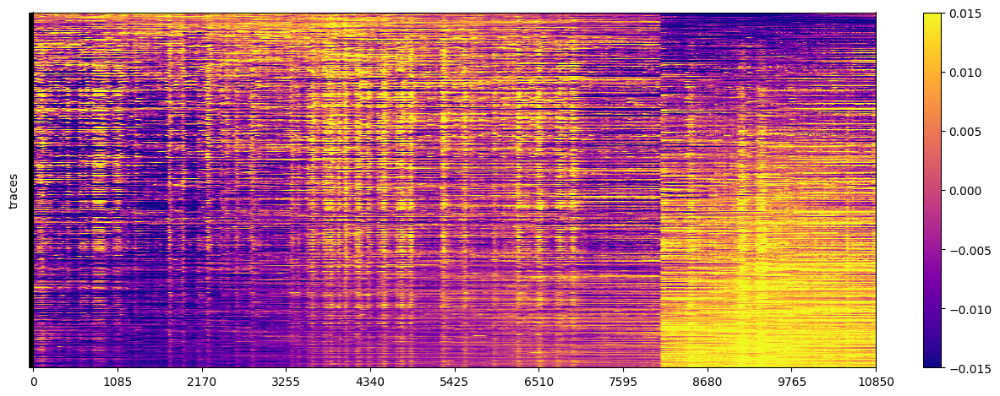

In [32]:
plot_utils.plot_heatmap_stack(
	traces_sorted[file_ids.index(0)],
	None,
	'traces', None,
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=True)

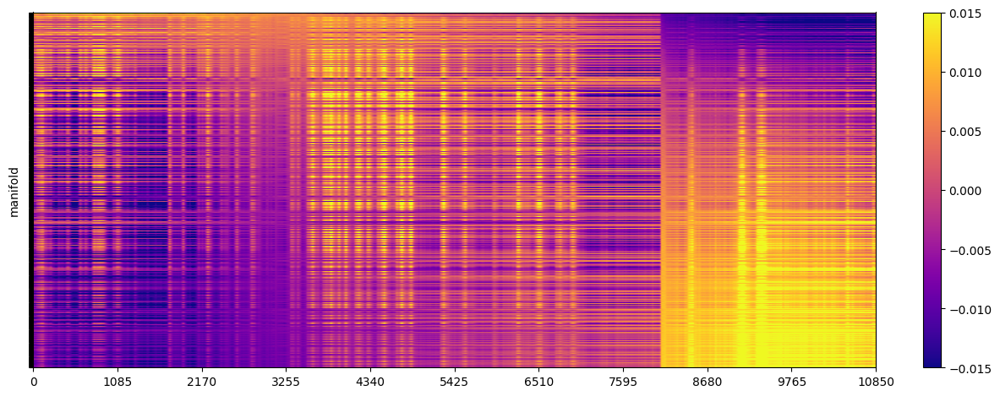

In [33]:
plot_utils.plot_heatmap_stack(
	traces_manifolds_sorted[file_ids.index(0)],
	None,
	'manifold', None,
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=True)

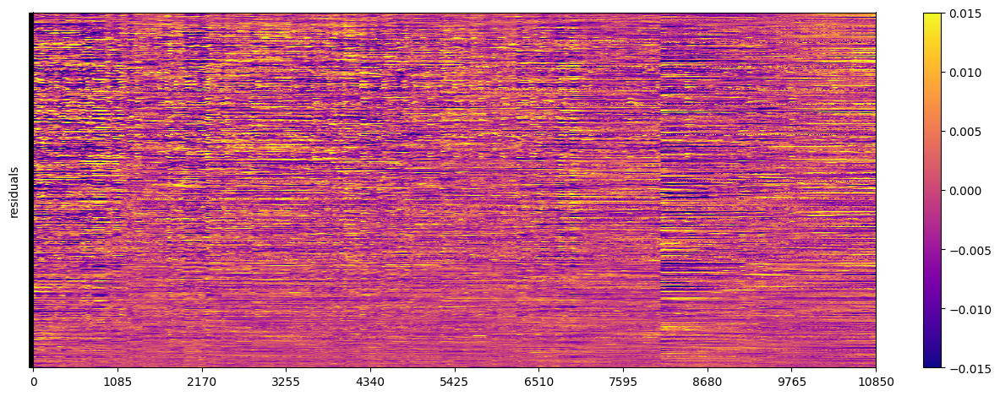

In [34]:
plot_utils.plot_heatmap_stack(
	traces_residuals_sorted_by_manifold[file_ids.index(0)],
	None,
	'residuals', None,
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=True)

# fly 2

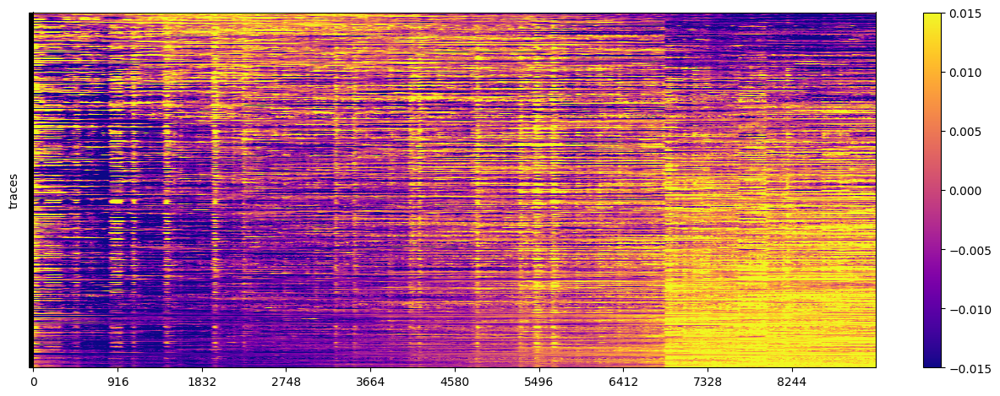

In [35]:
plot_utils.plot_heatmap_stack(
	traces_sorted[file_ids.index(2)],
	None,
	'traces', None,
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=True)

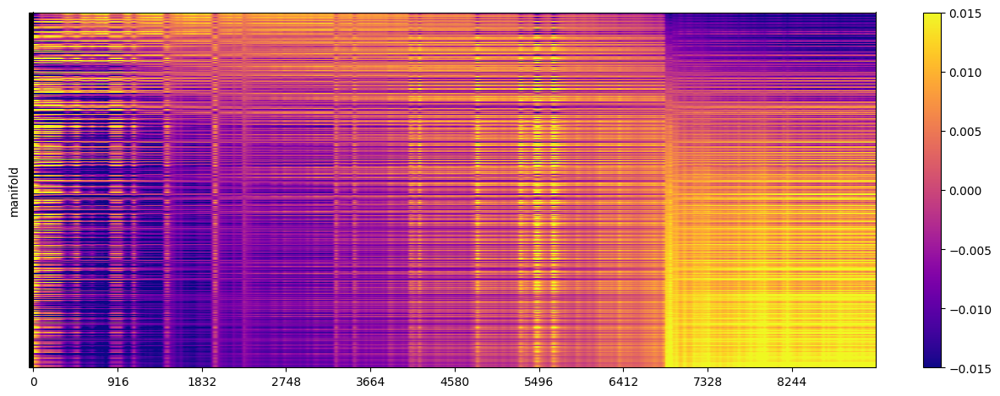

In [36]:
plot_utils.plot_heatmap_stack(
	traces_manifolds_sorted[file_ids.index(2)],
	None,
	'manifold', None,
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=True)

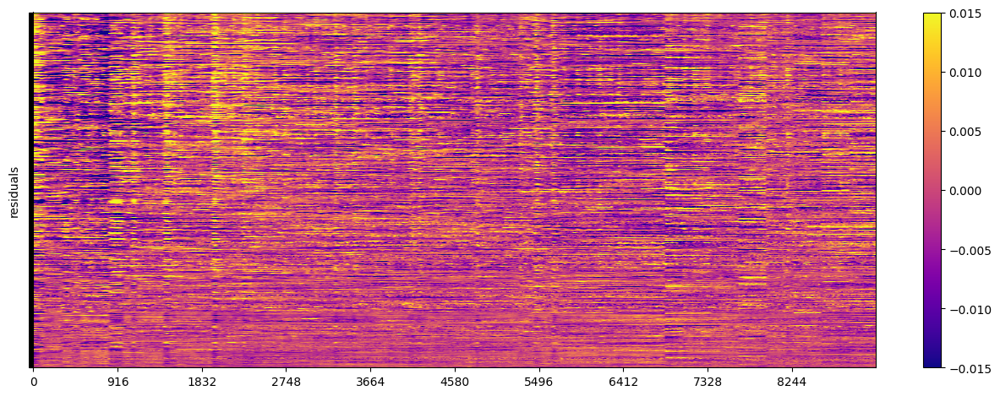

In [37]:
plot_utils.plot_heatmap_stack(
	traces_residuals_sorted_by_manifold[file_ids.index(2)],
	None,
	'residuals', None,
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=True)

# fly 3

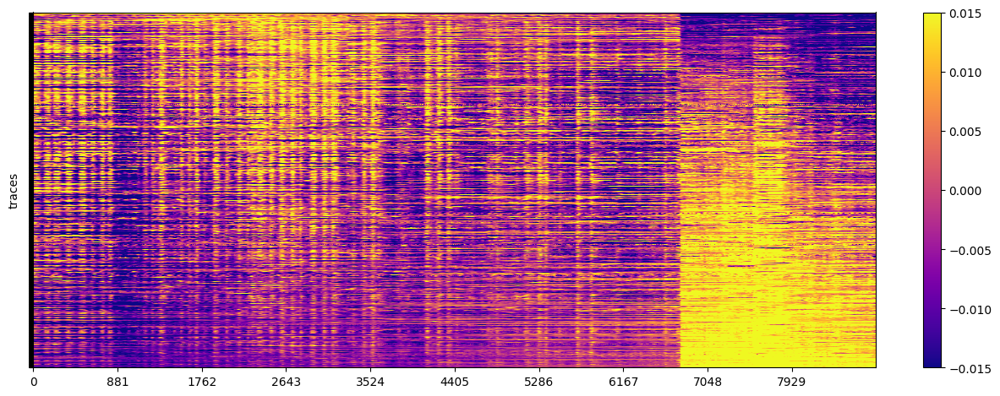

In [38]:
plot_utils.plot_heatmap_stack(
	traces_sorted[file_ids.index(3)],
	None,
	'traces', None,
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=True)

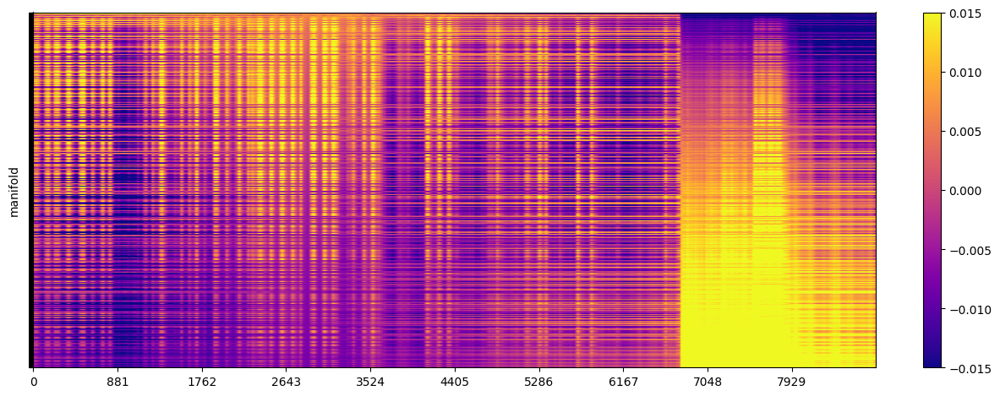

In [39]:
plot_utils.plot_heatmap_stack(
	traces_manifolds_sorted[file_ids.index(3)],
	None,
	'manifold', None,
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=True)

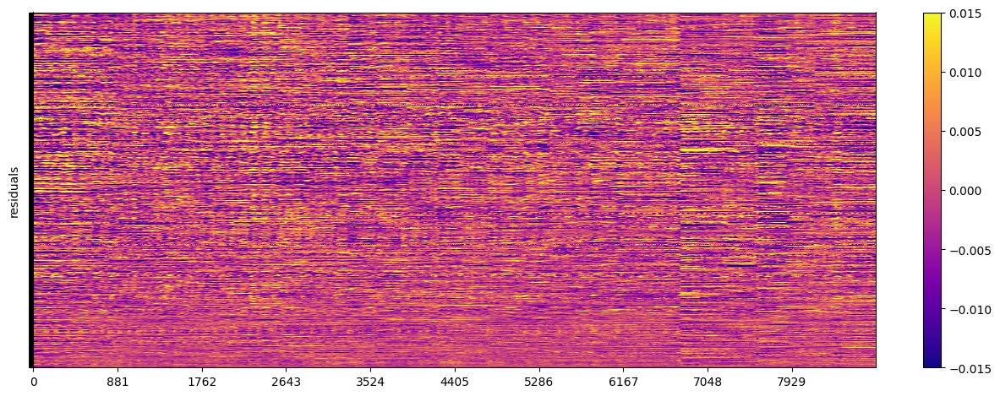

In [40]:
plot_utils.plot_heatmap_stack(
	traces_residuals_sorted_by_manifold[file_ids.index(3)],
	None,
	'residuals', None,
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=True)

# fly 8


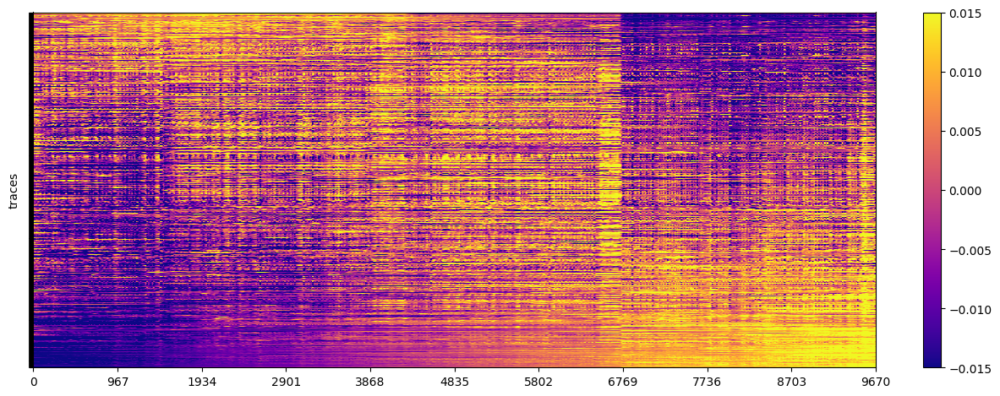

In [41]:
plot_utils.plot_heatmap_stack(
	traces_sorted[file_ids.index(8)],
	None,
	'traces', None,
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=True)

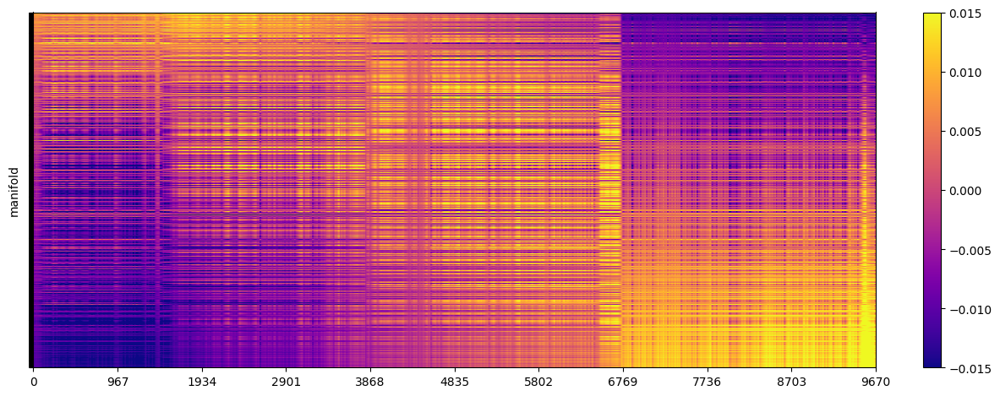

In [42]:
plot_utils.plot_heatmap_stack(
	traces_manifolds_sorted[file_ids.index(8)],
	None,
	'manifold', None,
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=True)

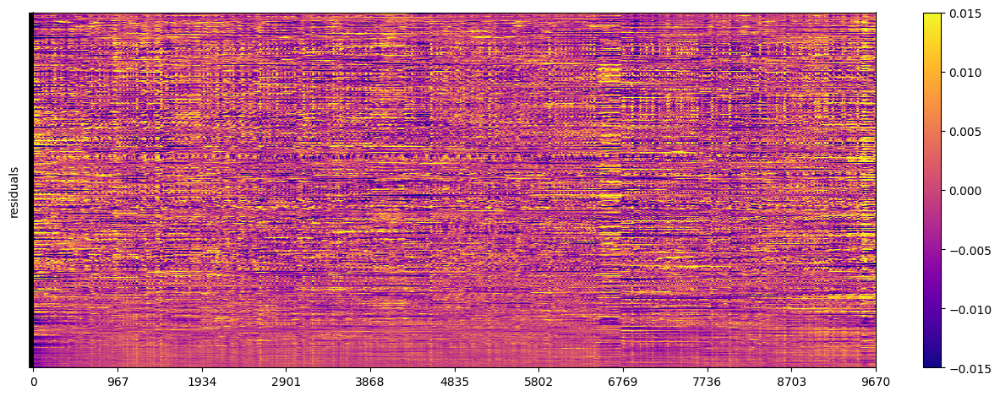

In [43]:
plot_utils.plot_heatmap_stack(
	traces_residuals_sorted_by_manifold[file_ids.index(8)],
	None,
	'residuals', None,
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=True)

# fly 9

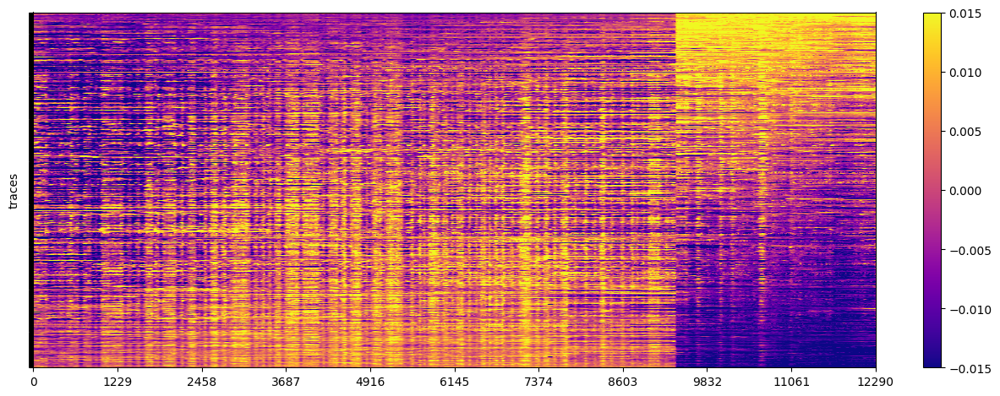

In [44]:
plot_utils.plot_heatmap_stack(
	traces_sorted[file_ids.index(9)],
	None,
	'traces', None,
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=True)

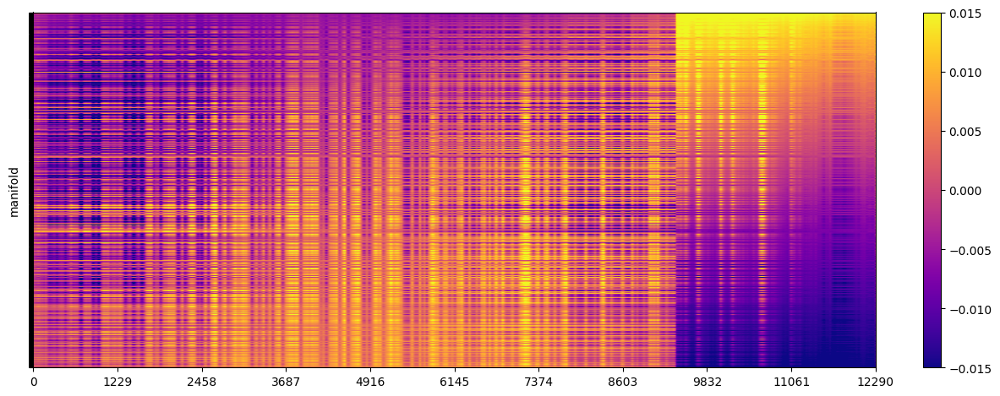

In [45]:
plot_utils.plot_heatmap_stack(
	traces_manifolds_sorted[file_ids.index(9)],
	None,
	'manifold', None,
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=True)

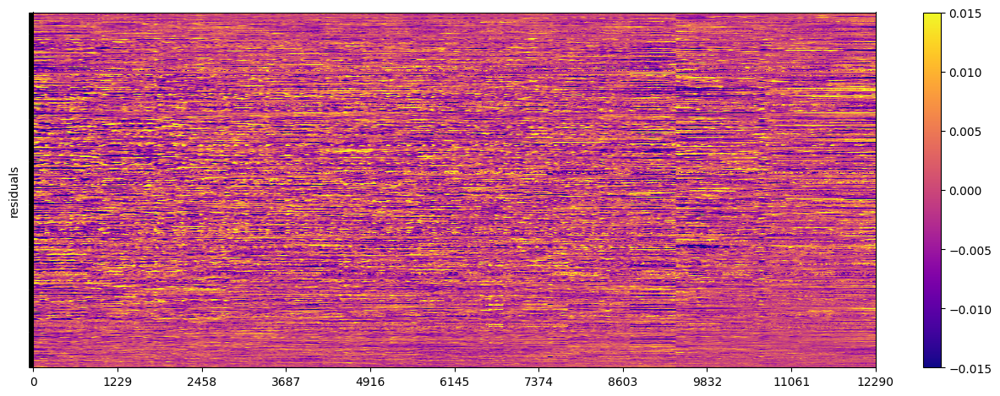

In [46]:
plot_utils.plot_heatmap_stack(
	traces_residuals_sorted_by_manifold[file_ids.index(9)],
	None,
	'residuals', None,
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=True)